# Research Activity
Create an example to generate anomalies on surfaces. For example, the MVTec AD Dataset contains samples of defects applied to train defect’s detection models for AI visual inspections. This research activity aims to create synthetic defects in surface images to be used in anomaly detection. Thus, choose one kind of defect that you prefer to be automatically created (cracks, stains, discoloration, etc.) and try to generate this defect on any surface.


# STEP 1 - Runtime configuration

In [2]:
import os, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cpu":
    print("Warning: CPU detected. Reduce N_CRACKS if generation is too slow.")

Device: cuda


# Step 2 - Installation of Packages

In [3]:
%pip -q install diffusers transformers accelerate safetensors scikit-image opencv-python-headless
%pip -q install -U torchao

# Step 3 - Image Download




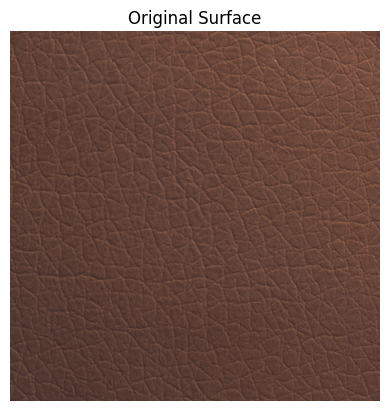

Successfully downloaded 1 image to /content/surfaces/047.png


In [11]:
import os, urllib.request
import matplotlib.pyplot as plt
from PIL import Image

# Your specific GitHub details
GITHUB_USER = "parpi13"
GITHUB_REPO = "mvtec-sample"
BRANCH = "main"
IMG_NAME = "047.png"

GOOD_DIR = "/content/surfaces"
os.makedirs(GOOD_DIR, exist_ok=True)

# Build the URL and download
url = f"https://raw.githubusercontent.com/{GITHUB_USER}/{GITHUB_REPO}/{BRANCH}/{IMG_NAME}"
dst = os.path.join(GOOD_DIR, IMG_NAME)

print(f"Downloading {url}...")
urllib.request.urlretrieve(url, dst)

# Set up the path variable that the rest of your notebook expects
good_paths = [dst]

# Show the image to confirm it worked
img = Image.open(good_paths[0]).convert("RGB")
plt.imshow(img)
plt.axis("off")
plt.title("Original Surface")
plt.show()

print(f"Successfully downloaded 1 image to {dst}")

# Step 4 - Difussion Model

In [6]:
from diffusers import AutoPipelineForText2Image

model_id = "stabilityai/sd-turbo"
dtype = torch.float16 if device == "cuda" else torch.float32

pipe = AutoPipelineForText2Image.from_pretrained(
    model_id,
    torch_dtype=dtype
).to(device)
print("Loaded:", model_id)

Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Loaded: stabilityai/sd-turbo


# Step 5 - Generating the defect

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/4 [00:00<?, ?it/s]

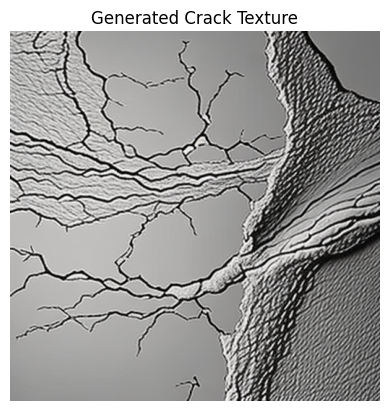

In [13]:
from diffusers import AutoPipelineForText2Image

pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo",
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
).to(device)

# Prompt tuned for leather
PROMPT = ("a photorealistic deep crack on a leather surface, dark branching lines, "
          "high detail, top-down view, isolated on a plain light gray background")

crack = pipe(
    prompt=PROMPT,
    num_inference_steps=4,
    guidance_scale=0.0,
    height=512,
    width=512
).images[0].convert("RGB")

crack.save("/content/crack_texture.png")
plt.imshow(crack)
plt.axis("off")
plt.title("Generated Crack Texture")
plt.show()

# Step 6 - Composite the defect on the leather


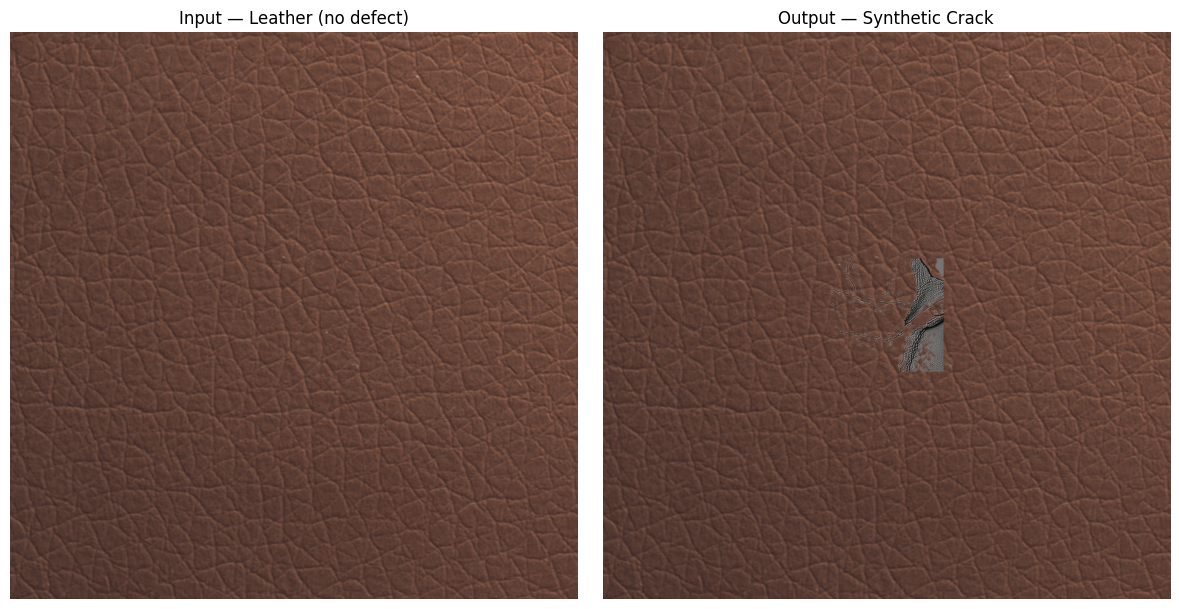

In [14]:
import cv2

def crack_mask(img, dark_thresh=120):
    """Extract an alpha mask. 120 works well for dark leather cracks."""
    g = np.array(img.convert("L"))
    m = (g < dark_thresh).astype(np.uint8) * 255
    m = cv2.medianBlur(m, 3)
    m = cv2.GaussianBlur(m, (5, 5), 0)
    return m.astype(np.float32) / 255.0

# Load the original leather image
orig = Image.open(good_paths[0]).convert("RGB")

# Scale and build mask
scale = 0.40
cw, ch = int(crack.size[0] * scale), int(crack.size[1] * scale)
crack_small = crack.resize((cw, ch), Image.LANCZOS)
alpha_mask  = crack_mask(crack_small)
alpha       = Image.fromarray((alpha_mask * 255).astype(np.uint8)).convert("L")

# Place in the center
W, H = orig.size
px = (W - cw) // 2
py = (H - ch) // 2

# Composite
synth = orig.copy()
synth.paste(crack_small, (px, py), alpha)

# Save and display
orig.save("/content/input_no_defect.png")
synth.save("/content/output_synthetic_defect.png")

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(orig)
ax[0].set_title("Input — Leather (no defect)")
ax[0].axis("off")

ax[1].imshow(synth)
ax[1].set_title("Output — Synthetic Crack")
ax[1].axis("off")

plt.tight_layout()
plt.savefig("/content/synthetic_defect_figure.png", dpi=150, bbox_inches="tight")
plt.show()

# Step 7 - Suggested Evaluation

In [18]:
from sklearn.neighbors import NearestNeighbors

print("--- Downstream Anomaly Detection (kNN) ---")

# Extract features from normal patches of the original image
def get_patch_features(image):
    W, H = image.size
    patch_w, patch_h = W // 4, H // 4
    feats = []
    for y in range(0, H - patch_h, patch_h):
        for x in range(0, W - patch_w, patch_w):
            patch = image.crop((x, y, x + patch_w, y + patch_h))
            feats.append(get_features(patch))
    return np.array(feats)

normal_feats = get_patch_features(orig)

# Fit a kNN model on the normal patches
knn = NearestNeighbors(n_neighbors=3)
knn.fit(normal_feats)

# Score the original (normal) patch vs the synthetic (defect) patch
normal_patch = orig.crop((px, py, px+cw, py+ch))
normal_score = knn.kneighbors(get_features(normal_patch).reshape(1, -1))[0].mean()

defect_patch = synth.crop((px, py, px+cw, py+ch))
defect_score = knn.kneighbors(get_features(defect_patch).reshape(1, -1))[0].mean()

print(f"Distance (Normal patch): {normal_score:.4f}")
print(f"Distance (Defect patch): {defect_score:.4f}")

if defect_score > normal_score:
    print("Result: The anomaly detector successfully flagged the synthetic defect.")
else:
    print("Result: The defect was not detected.")

--- Downstream Anomaly Detection (kNN) ---
Distance (Normal patch): 5.2601
Distance (Defect patch): 30.9493
Result: The anomaly detector successfully flagged the synthetic defect.
